In [2]:
#librerias para datos 
import pyreadstat as pdst 
import numpy as np
import pandas as pd
from functools import reduce #nose que es la verdad
#Librerias visualizacion
import matplotlib.pyplot as plt 
import seaborn as sns
#Librerias estimacion
import statsmodels.api as sm
import sklearn as sk
from scipy.optimize import minimize
from scipy.stats import chi2, norm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss
#librerias para descargar el endes de inei
from perustats.inei import INEIFetcher
#Pa saber dondtoy y si mi ruta existe o no :v:V:VV:V::V:
from pathlib import Path
import os as os

In [3]:
(INEIFetcher("endes", years=range(2018, 2019))
    .fetch_modules()
    .download(module_codes=[64, 65,66,69,70,73, 414])
    .organize(organize_by="module", operation="move"))



Output()

✓ Found 13 modules for ENDES

Output()

Output()

Output()

Files organized under data\microodatos_inei\endes\2_organized\by_module

INEIFetcher(survey='endes', years=[2018], modules=13)

In [4]:

archivos=(["0064_caracteristicas_del_hogar",
"0065_caracteristicas_de_la_vivienda",
"0066_datos_basicos_de_mef",
"0069_embarazo_parto_puerperio_y_lactancia",
"0070_inmunizacin_y_salud",
"0073_mortalidad_materna_-_violencia_familiar",
"0414_encuesta_de_salud"
])
en1=["h0","h1","h4","h23","41","42","43","83","84dv","91","94","95","0111","hm"] 
en2=["csalud01","csalud03","csalud07","csalud08","dit"]
encuesta= ["rec"+i for i in en1] +en2

In [5]:
dir0 = Path.cwd()
nombres=[]
df=[]
n_datas=0
for i in [2018]:
    for j in archivos:
        for k in encuesta:
            ruta=dir0 / r"data\microodatos_inei\endes\2_organized\by_module"/ j / f"{i}_{k}.sav"
            if os.path.exists(ruta):
                n_datas+=1
                nombres.append(f"{i}_{k}")
                df.append(pdst.read_sav(ruta, encoding="latin1")) #Lo de , encoding="latin1" salio de github xdxdxd https://github.com/tidyverse/haven/issues/615
            else:
                continue
print("correcto" if n_datas==len(df) else "REVISAAAAAAAAAAAAAAAAAAA")

correcto


In [6]:
hogar1=df[0][0].merge(df[4][0], on="HHID", how="inner")
print("\n Solo datos hogar:", len(hogar1), len(hogar1.columns))

miembro=df[1][0].merge(df[2][0], left_on=["HHID","HVIDX"], right_on=["HHID","IDXH4"], how="inner")
miembro=hogar1.merge(miembro, on="HHID", how="left")
print("\n Miembros de  hogar:", len(miembro), len(miembro.columns))

dmujer=df[6][0].merge(df[5][0], on="CASEID", how="inner")
dmujer=dmujer.merge(df[9][0], on="CASEID", how="inner")
dmujer=dmujer.merge(df[14][0], on="CASEID", how="inner")
dmujer=hogar1.merge(dmujer, on="HHID", how="right")

print("\n Mujeres:", len(dmujer), len(dmujer.columns))

niños=df[7][0].merge(df[8][0], left_on=["CASEID","MIDX"], right_on=["CASEID","IDX94"])
niños=niños.merge(df[10][0], left_on=["CASEID","MIDX"], right_on=["CASEID","HIDX"])
niños=niños.merge(df[11][0], left_on=["CASEID","MIDX"], right_on=["CASEID","IDX95"])
niños=niños.merge(dmujer, on="CASEID", how="left")
print("niños:", len(niños), len(niños.columns), "\n")

salud_adulto=df[15][0].merge(hogar1, left_on=["QHCLUSTER","QHNUMBER","QHHOME"],right_on=["HV001","HV002","HV002A"], how='left')
print("Salud:", len(salud_adulto), len(salud_adulto.columns), "\n")

salud_niño=df[16][0].merge(hogar1, left_on=["QHCLUSTER","QHNUMBER","QHHOME"],right_on=["HV001","HV002","HV002A"], how='left')
print("Salud:", len(salud_niño), len(salud_niño.columns), "\n")

for i in range(len(nombres)):
    print(i, f"{len(df[i][0])} in {nombres[i]}")


 Solo datos hogar: 37486 171

 Miembros de  hogar: 149727 225

 Mujeres: 34971 970
niños: 23089 1616 

Salud: 35388 441 

Salud: 46445 240 

0 37486 in 2018_rech0
1 147629 in 2018_rech1
2 147629 in 2018_rech4
3 2739 in 2018_rechm
4 37486 in 2018_rech23
5 38777 in 2018_rec91
6 39745 in 2018_rec0111
7 23089 in 2018_rec41
8 23089 in 2018_rec94
9 34996 in 2018_rec42
10 23089 in 2018_rec43
11 23089 in 2018_rec95
12 22842 in 2018_dit
13 162903 in 2018_rec83
14 34971 in 2018_rec84dv
15 35388 in 2018_csalud01
16 46445 in 2018_csalud08


In [7]:
mis_dfs = {"hogar": hogar1, "miem": miembro, "mujer": dmujer, "niño": niños,"salud adulto": salud_adulto,"salud niño": salud_niño}
df=[]
for i,j in mis_dfs.items():
    existe=j.notna().sum()
    print(f"{i} : ",len(j.columns),len(existe[existe>0].index))
    df.append(j[existe[existe>0].index])


hogar :  171 135
miem :  225 188
mujer :  970 733
niño :  1616 1243
salud adulto :  441 374
salud niño :  240 203


In [8]:
def limpiar(serie):
    return np.where(serie == 1, 1.0, np.where(serie == 0, 0.0, np.nan))

def inv_limpiar(serie):
    return np.where(serie == 1, 0.0, np.where(serie == 0, 1.0, np.nan))

def construir_ubigeo_prov(df_in):
    dep_s = df_in.HV024.fillna(0).astype(int).astype(str).str.zfill(2)
    prv_s = df_in.SHPROVIN.fillna(0).astype(int).astype(str).str.zfill(2)
    ub = dep_s + prv_s
    return ub.where(ub != "0000", np.nan)


def media_ponderada_grupo(df_in, group_cols, var_cols, peso_col):
    resultados = {}
    w = df_in[peso_col]
    for v in var_cols:
        val = df_in[v]
        temp = pd.DataFrame({
            "g1": df_in.loc[:, group_cols[0]],
            "vw": val * w,
            "w": np.where(val.notna(), w, np.nan)
        })
        agg = temp.groupby("g1")[["vw", "w"]].sum()
        resultados[v] = agg["vw"] / agg["w"]
    out_df = pd.DataFrame(resultados)
    out_df.index.names = group_cols
    return out_df.reset_index()


def media_n(df_in, group_cols, var_cols):
    resultados = {}
    for v in var_cols:
        temp = pd.DataFrame({
            "g1": df_in.loc[:, group_cols[0]],
            "vw": df_in[v]
        })
        agg = temp.groupby("g1")[["vw"]].mean()
        resultados[v] = agg["vw"]
    out_df = pd.DataFrame(resultados)
    out_df.index.names = group_cols
    return out_df.reset_index()


In [9]:
#    grupao=dm[["UBIGEO_PROV",nuevo]].dropna().groupby("UBIGEO_PROV")[nuevo].size()
#    print(np.where(grupao>=10,0,1).sum(),np.where(grupao>=20,0,1).sum(),np.where(grupao>=30,0,1).sum(),len(grupao))
#    grupao=dm[dm["V481G"] == 1][["UBIGEO_PROV",nuevo]].dropna().groupby("UBIGEO_PROV")[nuevo].size()
#    print("SIS ",np.where(grupao>=10,0,1).sum(),np.where(grupao>=20,0,1).sum(),np.where(grupao>=30,0,1).sum(),len(grupao))

In [10]:
#MUJEREES
dm = dmujer.copy()
dm["UBIGEO_PROV"] = construir_ubigeo_prov(dm)
dm["PESO"]=dm["V005"]/ 1e6

for codigo , nuevo in [("V467H", "no_falta_personal"), ("V467I", "no_falta_medicinas"),
                       ("V467D", "no_accesibilidad_fisica"), ("V467G", "no_falta_pers_fem")]:
    dm[nuevo] = inv_limpiar(dm[codigo])   
     
dm_filtro=dm[dm["V481G"] == 1]

agg_dmujer = media_ponderada_grupo(
    dm_filtro.dropna(subset=["UBIGEO_PROV"]),
    ["UBIGEO_PROV"],
    ["no_falta_personal", "no_falta_medicinas", "no_accesibilidad_fisica", "no_falta_pers_fem", ],
    "PESO"
)
agg_dmujer[["no_falta_personal", "no_falta_medicinas", "no_accesibilidad_fisica", "no_falta_pers_fem"]].corr()


,no_falta_personal,no_falta_medicinas,no_accesibilidad_fisica,no_falta_pers_fem
no_falta_personal,1.000000,0.761443,0.389921,0.517148
no_falta_medicinas,0.761443,1.000000,0.325262,0.419087
no_accesibilidad_fisica,0.389921,0.325262,1.000000,0.564378
no_falta_pers_fem,0.517148,0.419087,0.564378,1.000000


In [11]:
# Nacimientos
ni = niños.copy()
ni["UBIGEO_PROV"] = construir_ubigeo_prov(ni)
ni["PESO"]=ni["V005"] / 1e6

ni["med_prenatal"] = limpiar(ni["M2A"])
ni["suple_hierro"] = limpiar(ni["M45"])
#TAMIZAJE INICIAL
ni["tam_sif"] = limpiar(ni["S411G"])
ni["tam_vih"] = limpiar(ni["S411H"])
ni["tam_hep"] = np.where(ni["QI411_M"] == 1, 1.0, np.where(ni["QI411_M"] == 2, 0.0, np.nan))

#Examenes
for c,ex in [("M42A", "peso"), ("S411B","Barriga"), ("M42C","Press"), ("M42D", "Orina"), ("M42E","Sangre"), ("S411F","Latidos")]:
        ni[f"ex_{ex}"] = limpiar(ni[c])

#Le dieron informacion al momento del parto (No creo que m44 sea muy informativo es mas condicional creo que m43 ya es suficiente. es como medir altura y ancho xd)
for c,ex in [("M43","compli"), ("M44","donde_ir"), ("S411I","aliment"), ("S411K","prep_lactancia"), ("S411L","lactancia")]:
    ni[f"inf_{ex}"] = limpiar(ni[c])

#diagnostico anemia (ESTO ES CONFUSO NOSE COMO PLANTEARLO DX)
ni["diag_anem"] = np.where(ni["QI422A"].isin([1, 2]), 1.0, np.where(ni["QI422A"] == 3, 0.0, np.nan))
ni["trat_anem"] = np.where(ni["QI422A"]== 1, 1.0, np.where(ni["QI422A"].isin([2,3]), 0.0, np.nan))

m_minsa = (limpiar(ni["M57E"]) == 1) | (limpiar(ni["M57F"]) == 1) | (limpiar(ni["M57G"]) == 1)
m_sis=(ni["S432"]==1)
ni_filtro=ni[m_minsa]

variables_creadas_ni = [
    "med_prenatal",
    "suple_hierro",
    "tam_sif",
    "tam_vih",
    "tam_hep",
    "ex_peso",
    "ex_Barriga",
    "ex_Press",
    "ex_Orina",
    "ex_Sangre",
    "ex_Latidos",
    "inf_compli",
    "inf_donde_ir",
    "inf_aliment",
    "inf_prep_lactancia",
    "inf_lactancia",
    "diag_anem",
    "trat_anem"
]


agg_prenatal = media_n(
    ni_filtro.dropna(subset=["UBIGEO_PROV"]),
    ["UBIGEO_PROV"],
    variables_creadas_ni
)

grupao=ni_filtro[["UBIGEO_PROV","tam_vih"]].dropna().groupby("UBIGEO_PROV")["tam_vih"].size()
print("SIS ",np.where(grupao>=10,0,1).sum(),np.where(grupao>=20,0,1).sum(),np.where(grupao>=30,0,1).sum(),len(grupao))

SIS  14 50 68 187


In [12]:
s426fb = ni["S426FB"]
ni["espera"] = np.where(ni["S426FB"].isin([100, 200, 300]), 0.0,
            np.where((ni["S426FB"] >= 101) & (ni["S426FB"] <= 148), ni["S426FB"] - 100.0,
            np.where((ni["S426FB"] >= 201) & (ni["S426FB"] <= 248), (ni["S426FB"] - 200.0) * 24.0,
            np.where((ni["S426FB"] >= 301) & (ni["S426FB"] <= 348), (ni["S426FB"] - 300.0) * 168.0, np.nan))))


ni["med_parto"] = limpiar(ni["M3A"])
ni["contacto_piel"] = limpiar(ni["S436C"]) # Probable Tenga que ver con la calidad del profesional
ni["inf_lac_post"] = limpiar(ni["S441"])
ni["ctrl_pos_nat"] = limpiar(ni["M70"])

m_minsa=ni["M15"].isin([21, 24, 25])
ni_filtro=ni[m_minsa]

agg_parto = media_n(
    ni_filtro.dropna(subset=["UBIGEO_PROV"]),
    ["UBIGEO_PROV"],
    ["espera", "med_parto", "contacto_piel", "inf_lac_post","ctrl_pos_nat"],
)



In [13]:
ni["med_cred"] = limpiar(ni["S466AA"])
ni["pro_continuidad_cred"] = np.where((ni["S466C"] >= 0) & (ni["S466C"] <= 20), ni["S466C"], np.nan)
ni["diag_anem_infan"] = np.where(ni["QI465ED_CC"].isin([1, 2]), 1.0, np.where(ni["QI465ED_CC"] == 3, 0.0, np.nan))
ni["trat_anem_infan"] = np.where(ni["QI465ED_CC"]== 1, 1.0, np.where(ni["QI465ED_CC"].isin([2,3]), 0.0, np.nan))


m_minsa=ni["S466B"].isin([21, 24, 25])
ni_filtro=ni[m_minsa]

agg_cred = media_n(
    ni_filtro.dropna(subset=["UBIGEO_PROV"]),
    ["UBIGEO_PROV"],
    ["med_cred", "pro_continuidad_cred", "diag_anem_infan","trat_anem_infan"]
)

In [14]:
#SALUD ADUUULOTROSOSOT
sa = salud_adulto.copy()
sa["UBIGEO_PROV"] = construir_ubigeo_prov(sa)
sa["PESO"] = sa["HV005"] / 1e6

sa_filtro=sa[sa["QS27"]=="A"]

# Entrega de resultados de Papanicolaou y chequeo oncológico, etc 
sa["opo_entrega_resultados_pap"] = np.where(sa["QS413"] == 1, 1.0, np.where(sa["QS413"] == 2, 0.0, np.nan))

sa_filtro=sa[sa["QS27"]=="A"]
agg_sa = media_n(
    sa_filtro.dropna(subset=["UBIGEO_PROV"]),
    ["UBIGEO_PROV"],
    ["opo_entrega_resultados_pap"]
)



# Salud Niño
sn = salud_niño.copy()
sn["UBIGEO_PROV"] = construir_ubigeo_prov(sn)
sn["PESO"] = sn["HV005"] / 1e6

sn["info_higiene_bucal"] = np.where(sn["QS806"] == 1, 1.0, np.where(sn["QS806"] == 2, 0.0, np.nan))

m_minsa=sn["QS805"].isin([10, 14, 40])
sn_filtro=sn[m_minsa]

agg_sn = media_n(
    sn_filtro.dropna(subset=["UBIGEO_PROV"]),
    ["UBIGEO_PROV"],
    ["info_higiene_bucal"],
)



In [15]:
agg_prenatal["res_anem_prenatal"] = (
    agg_prenatal["trat_anem"] / agg_prenatal["diag_anem"].replace(0, np.nan)
)
agg_cred["res_anem_infan"] = (
    agg_cred["trat_anem_infan"] / agg_cred["diag_anem_infan"].replace(0, np.nan)
)

In [16]:

lista_tablas_prov = [
    agg_dmujer,    
    agg_prenatal, 
    agg_parto,    
    agg_cred,   
    agg_sa,       
    agg_sn      
]

base_sis_minsa = reduce(
    lambda left, right: pd.merge(left, right, on="UBIGEO_PROV", how="outer"),
    lista_tablas_prov
).sort_values("UBIGEO_PROV").reset_index(drop=True)

base_sis_minsa["rapidez_parto"] = 1.0 / (1.0 + base_sis_minsa["espera"])


In [17]:
vars_percepcion_sis = [
    "no_falta_personal",
    "no_falta_medicinas",
    "no_accesibilidad_fisica",
    "no_falta_pers_fem"
]

In [18]:
variables_minsa= [
        "ex_peso", "ex_Barriga", "ex_Press", "ex_Orina", "ex_Sangre", "ex_Latidos",
        "tam_sif", "tam_vih", "tam_hep", "suple_hierro",
        "inf_compli", "inf_aliment", "inf_prep_lactancia", "inf_lactancia", "inf_lac_post", "info_higiene_bucal",
        "med_prenatal", "med_parto", "med_cred", "rapidez_parto",
        "contacto_piel", "ctrl_pos_nat", "pro_continuidad_cred", "opo_entrega_resultados_pap",
        "res_anem_prenatal", "res_anem_infan"
]

<Axes: >

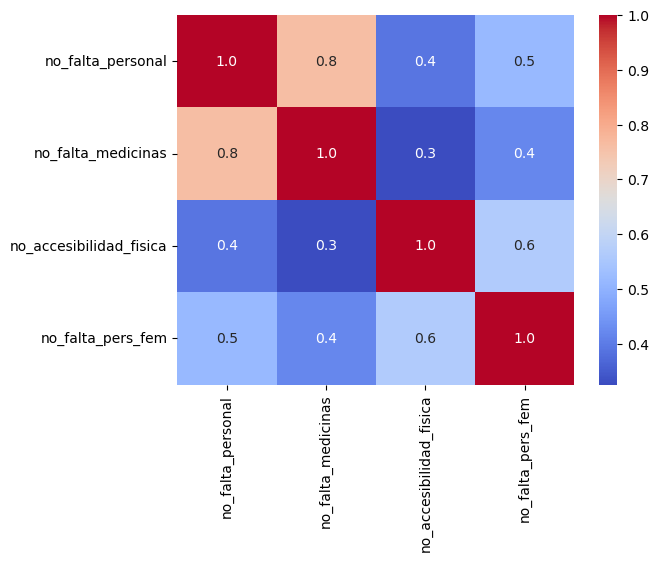

In [19]:
sns.heatmap(base_sis_minsa[vars_percepcion_sis].corr(),annot=True,cmap="coolwarm", fmt=".1f")

In [20]:
def pecea(base_sis_minsa, vars_percepcion_sis, diferenciador, n_pcs_heatmap, alpha=0.05):
    sub_df = base_sis_minsa[vars_percepcion_sis].copy()
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    X_std = scaler.fit_transform(imputer.fit_transform(sub_df))
    
    
    chi2_bartlett, p_value_bartlett = calculate_bartlett_sphericity(X_std)
    print(f"Bartlett p-valor: {p_value_bartlett:.4e}")
    kmo_per_variable, kmo_total = calculate_kmo(X_std)
    print(f"KMO: {kmo_total:.4f}")
    
    
    
    pca = PCA() 
    PCs_array = pca.fit_transform(X_std)
    lambdas = pca.explained_variance_



    n = X_std.shape[0] 
    z = norm.ppf(1 - alpha / 2)
    margin_of_error = z * np.sqrt(2 / n)
    
    lambda_lower = lambdas / (1 + margin_of_error)
    lambda_upper = lambdas / (1 - margin_of_error)
    ic_df = pd.DataFrame({
        'PC': range(1, len(lambdas) + 1),
        'Lambda': lambdas,
        'Limite_Inf': lambda_lower,
        'Limite_Sup': lambda_upper
    })


    pc_columns = [f'{diferenciador}_PC{i+1}' for i in range(PCs_array.shape[1])]
    PCs_df = pd.DataFrame(PCs_array, columns=pc_columns, index=sub_df.index)

    correlaciones = pca.components_.T * np.sqrt(pca.explained_variance_)
    corr_df = pd.DataFrame(
        correlaciones, 
        columns=pc_columns,
        index=vars_percepcion_sis
    )

    plt.figure(figsize=(8, 5))
    x_vals = range(1, len(lambdas) + 1)
    
    plt.plot(x_vals, lambdas, marker='o', linestyle='--', color="#000000")
    plt.fill_between(x_vals, lambda_lower, lambda_upper, color="#374550", alpha=0.2, 
                     label=f'Banda de Confianza al {(1-alpha)*100:.0f}%')
    
    plt.axhline(y=1, color='black', linestyle='-')
    
    plt.xlabel('Número de Componente')
    plt.ylabel('Varianza Explicada (Lambda)')
    plt.xticks(x_vals)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    corr_subset = corr_df.iloc[:, :n_pcs_heatmap]
    plt.figure(figsize=(10, max(8, len(vars_percepcion_sis) * 0.4)))  
    sns.heatmap(corr_subset, annot=True, cmap='coolwarm', center=0, fmt='.2f', vmin=-1, vmax=1)   
    plt.show()

    return PCs_df

Bartlett p-valor: 6.2242e-60
KMO: 0.6745


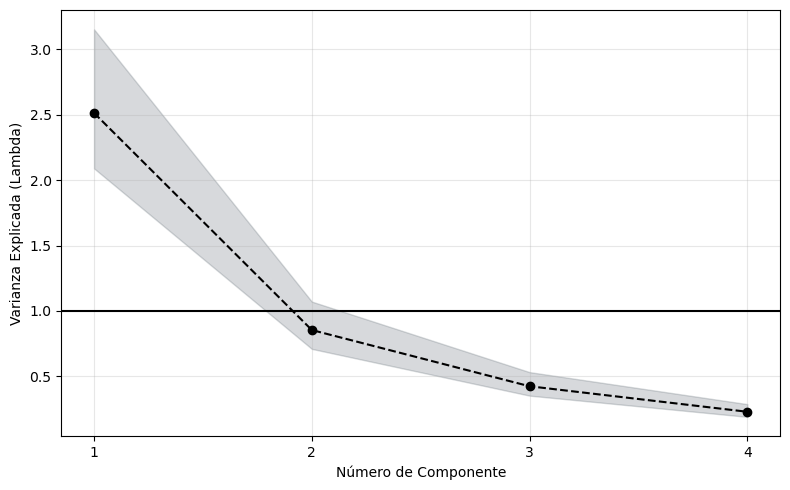

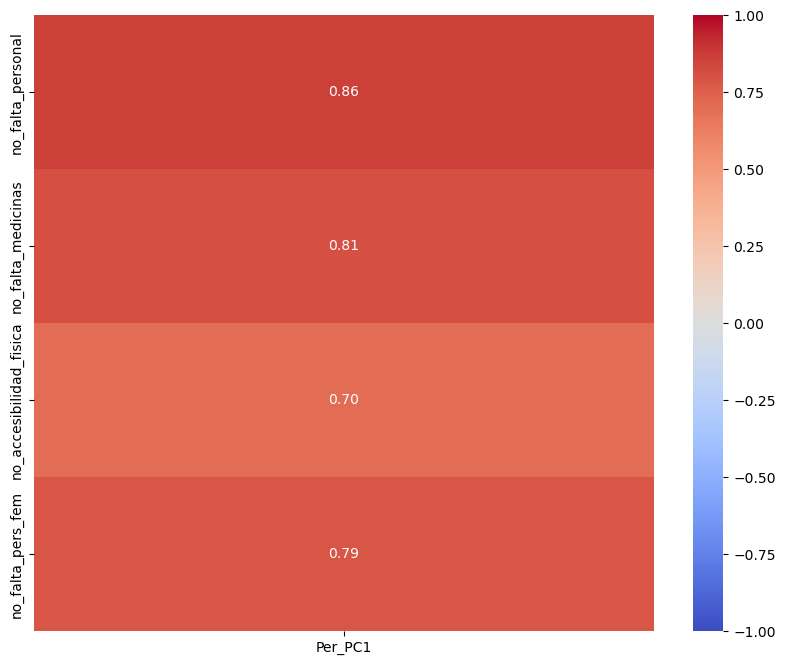

Bartlett p-valor: 6.8961e-191
KMO: 0.6882


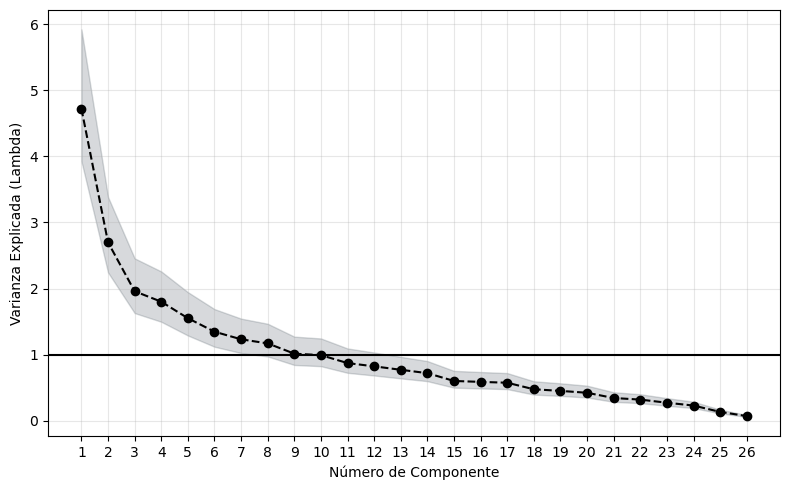

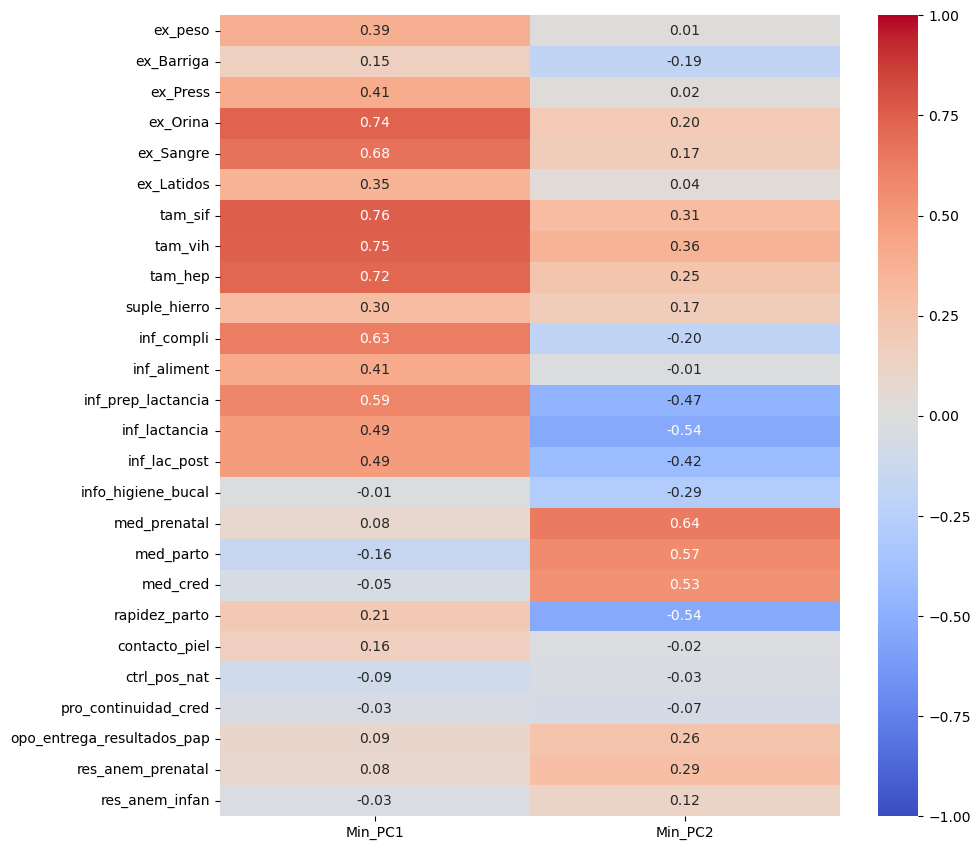

In [21]:
pca=pecea(base_sis_minsa,vars_percepcion_sis,"Per",1)
pca2=pecea(base_sis_minsa,variables_minsa,"Min",2)

<Axes: >

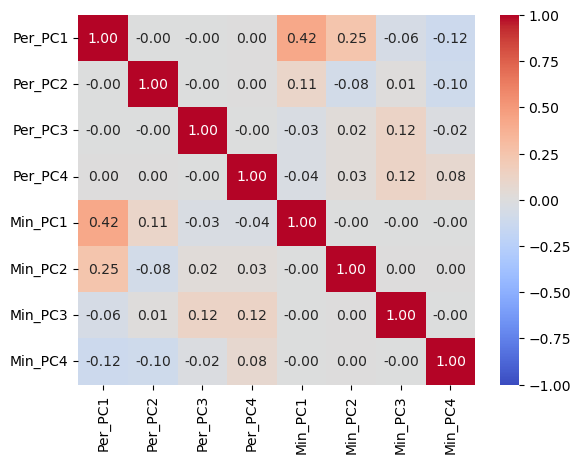

In [22]:
base_final = base_sis_minsa.join(pca).join(pca2)

core=base_final[["Per_PC1","Per_PC2","Per_PC3","Per_PC4","Min_PC1","Min_PC2","Min_PC3","Min_PC4"]].corr()
sns.heatmap(core, annot=True, cmap='coolwarm', center=0, fmt='.2f', vmin=-1, vmax=1)   


In [23]:
base_final_final=base_final[["UBIGEO_PROV","Per_PC1","Min_PC1","Min_PC2"]]

HASTA AHI LLEGA LA CALIDAD 

In [24]:
micro_miem = miembro.copy()
micro_miem["UBIGEO_PROV"] = construir_ubigeo_prov(micro_miem)

if "HV102" in micro_miem.columns:
    micro_miem = micro_miem[micro_miem["HV102"] == 1].copy()
if "HV105" in micro_miem.columns:
    micro_miem = micro_miem[micro_miem["HV105"] >= 18].copy()

# TENENCIA DE SEGUROS PRIVADOS
micro_miem["tiene_seguro_privado"] = np.where(
    (micro_miem["SH11D"] == 1) | (micro_miem["SH11E"] == 1), 1.0,
    np.where((micro_miem["SH11D"] == 0) & (micro_miem["SH11E"] == 0), 0.0, np.nan)
)

# Variables control 
micro_miem["riqueza_z"] = (micro_miem["HV271"] - micro_miem["HV271"].mean()) / micro_miem["HV271"].std()
micro_miem["educacion_anios"] = np.where(micro_miem["HV108"].isin([98, 99]), np.nan, micro_miem["HV108"])
micro_miem["edad"] = micro_miem["HV105"]
micro_miem["urbano"] = np.where(micro_miem["HV025"] == 1, 1.0, 0.0)
micro_miem["riqueza"] = micro_miem["HV271"]
data_logit_miem = micro_miem.merge(base_final_final, on="UBIGEO_PROV", how="inner")



In [25]:

vars_pca = ["Per_PC1","Min_PC1",  "Min_PC2"] #
vars_controles = ["riqueza_z", "educacion_anios", "edad"]
cols_modelo = ["tiene_seguro_privado", "UBIGEO_PROV"] + vars_pca + vars_controles +["riqueza"]

df_clean = data_logit_miem[cols_modelo].dropna().copy()
df_clean["tiene_seguro_privado"] = df_clean["tiene_seguro_privado"].astype(int)

In [26]:
X= sm.add_constant(df_clean[vars_pca])
Y = df_clean["tiene_seguro_privado"]
logit_solo_pca = sm.Logit(Y, X).fit(cov_type="HC1", disp=False)
print("MODELO 1: LOGIT 3 PCAs DEL SIS/MINSA ")
print(logit_solo_pca.summary())



MODELO 1: LOGIT 3 PCAs DEL SIS/MINSA 
                            Logit Regression Results                            
Dep. Variable:     tiene_seguro_privado   No. Observations:                84633
Model:                            Logit   Df Residuals:                    84629
Method:                             MLE   Df Model:                            3
Date:                  Sat, 14 Nov 2026   Pseudo R-squ.:                 0.09867
Time:                          19:36:30   Log-Likelihood:                -7658.0
converged:                         True   LL-Null:                       -8496.4
Covariance Type:                    HC1   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -4.9989      0.059    -84.971      0.000      -5.114      -4.884
Per_PC1        0.0597      0.026      2.324      0.020       0.009       0.11

In [27]:
X_con_controles = sm.add_constant(df_clean[[vars_pca[0],vars_pca[2]] + vars_controles])
logit_completo = sm.Logit(Y, X_con_controles).fit(cov_type="HC1", disp=False)
print(logit_completo.summary())


ame_m2 = logit_completo.get_margeff(at="overall", method="dydx")
print(ame_m2.summary())

                            Logit Regression Results                            
Dep. Variable:     tiene_seguro_privado   No. Observations:                84633
Model:                            Logit   Df Residuals:                    84627
Method:                             MLE   Df Model:                            5
Date:                  Sat, 14 Nov 2026   Pseudo R-squ.:                  0.3026
Time:                          19:36:30   Log-Likelihood:                -5925.8
converged:                         True   LL-Null:                       -8496.4
Covariance Type:                    HC1   LLR p-value:                     0.000
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -9.1190      0.201    -45.289      0.000      -9.514      -8.724
Per_PC1            -0.1741      0.030     -5.718      0.000      -0.234      -0.114
Min_PC2         

In [28]:
def calcular_aic(modelo, X, y):
    k = X.shape[1] + 1 
    probabilidades = modelo.predict_proba(X)[:, 1]
    N = len(y)
    log_likelihood = -log_loss(y, probabilidades) * N
    aic = 2 * k - 2 * log_likelihood
    return aic

In [29]:
def calcular_bic(modelo, X, y):
    k = X.shape[1] + 1 
    probabilidades = modelo.predict_proba(X)[:, 1]
    N = len(y)
    log_likelihood = -log_loss(y, probabilidades) * N
    aic = np.log(N)* k - 2 * log_likelihood
    return aic

In [30]:
vars_controles = ["riqueza", "educacion_anios", "edad"]


X_all = df_clean[vars_pca + vars_controles]
y_all = df_clean["tiene_seguro_privado"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

scaler = StandardScaler()
X_tr_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_all.columns, index=X_train.index)
X_va_s = pd.DataFrame(scaler.transform(X_val), columns=X_all.columns, index=X_val.index)
X_te_s = pd.DataFrame(scaler.transform(X_test), columns=X_all.columns, index=X_test.index)

clf_base = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s[vars_controles], y_train)
clf_pca  = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s[[vars_pca[0]] + vars_controles], y_train)
clf_pc1  = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s[[vars_pca[1]] + vars_controles], y_train)
clf_pc2  = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s[[vars_pca[2]] + vars_controles], y_train)
clf_23   = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s[vars_pca[1:] + vars_controles], y_train)
clf_13   = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s[[vars_pca[0]]+ [vars_pca[2]] + vars_controles], y_train) # Corregida la concatenación de listas
clf_12   = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s[vars_pca[:2] + vars_controles], y_train) # Eliminado el ']' sobrante
clf_completo = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s[vars_pca + vars_controles], y_train)



prob_base = clf_base.predict_proba(X_te_s[vars_controles])[:, 1]
prob_pca  = clf_pca.predict_proba(X_te_s[[vars_pca[0]] + vars_controles])[:, 1]
prob_pc1  = clf_pc1.predict_proba(X_te_s[[vars_pca[1]] + vars_controles])[:, 1]
prob_pc2  = clf_pc2.predict_proba(X_te_s[[vars_pca[2]] + vars_controles])[:, 1]
prob_23   = clf_23.predict_proba(X_te_s[vars_pca[1:] + vars_controles])[:, 1]
prob_13   = clf_13.predict_proba(X_te_s[[vars_pca[0], vars_pca[2]] + vars_controles])[:, 1]
prob_12   = clf_12.predict_proba(X_te_s[vars_pca[:2] + vars_controles])[:, 1]
prob_completo = clf_completo.predict_proba(X_te_s[vars_pca + vars_controles])[:, 1]


probs_dict = {
    "Base (Solo Controles)": prob_base,
    "PC1 + Controles": prob_pca,
    "PC2 + Controles": prob_pc1,
    "PC3 + Controles": prob_pc2,
    "PC2 y PC3 + Controles": prob_23,
    "PC1 y PC3 + Controles": prob_13,
    "PC1 y PC2 + Controles": prob_12,
    "Modelo Completo": prob_completo
}

for nombre, prob in probs_dict.items():
    print(f"{nombre} ")
    print(f" ROC-AUC : {roc_auc_score(y_test, prob):.4f}")
    print(f" PR-AUC  : {average_precision_score(y_test, prob):.4f}")
    print(f" Log-Loss: {log_loss(y_test, prob):.4f}\n")



Base (Solo Controles) 
 ROC-AUC : 0.9180
 PR-AUC  : 0.2050
 Log-Loss: 0.0699

PC1 + Controles 
 ROC-AUC : 0.9180
 PR-AUC  : 0.2002
 Log-Loss: 0.0700

PC2 + Controles 
 ROC-AUC : 0.9190
 PR-AUC  : 0.1964
 Log-Loss: 0.0698

PC3 + Controles 
 ROC-AUC : 0.9250
 PR-AUC  : 0.2577
 Log-Loss: 0.0675

PC2 y PC3 + Controles 
 ROC-AUC : 0.9253
 PR-AUC  : 0.2558
 Log-Loss: 0.0675

PC1 y PC3 + Controles 
 ROC-AUC : 0.9251
 PR-AUC  : 0.2526
 Log-Loss: 0.0675

PC1 y PC2 + Controles 
 ROC-AUC : 0.9188
 PR-AUC  : 0.1951
 Log-Loss: 0.0699

Modelo Completo 
 ROC-AUC : 0.9252
 PR-AUC  : 0.2523
 Log-Loss: 0.0675



In [31]:


aic_base = calcular_aic(clf_base, X_tr_s[vars_controles], y_train)
aic_pca  = calcular_aic(clf_pca, X_tr_s[[vars_pca[0]] + vars_controles], y_train)
aic_pc1  = calcular_aic(clf_pc1, X_tr_s[[vars_pca[1]] + vars_controles], y_train)
aic_pc2  = calcular_aic(clf_pc2, X_tr_s[[vars_pca[2]] + vars_controles], y_train)
aic_23   = calcular_aic(clf_23, X_tr_s[vars_pca[1:] + vars_controles], y_train)
aic_13   = calcular_aic(clf_13, X_tr_s[[vars_pca[0], vars_pca[2]] + vars_controles], y_train)
aic_12   = calcular_aic(clf_12, X_tr_s[vars_pca[:2] + vars_controles], y_train)
aic_completo = calcular_aic(clf_completo, X_tr_s[vars_pca + vars_controles], y_train)


bic_base = calcular_bic(clf_base, X_tr_s[vars_controles], y_train)
bic_pca  = calcular_bic(clf_pca, X_tr_s[[vars_pca[0]] + vars_controles], y_train)
bic_pc1  = calcular_bic(clf_pc1, X_tr_s[[vars_pca[1]] + vars_controles], y_train)
bic_pc2  = calcular_bic(clf_pc2, X_tr_s[[vars_pca[2]] + vars_controles], y_train)
bic_23   = calcular_bic(clf_23, X_tr_s[vars_pca[1:] + vars_controles], y_train)
bic_13   = calcular_bic(clf_13, X_tr_s[[vars_pca[0], vars_pca[2]] + vars_controles], y_train)
bic_12   = calcular_bic(clf_12, X_tr_s[vars_pca[:2] + vars_controles], y_train)
bic_completo = calcular_bic(clf_completo, X_tr_s[vars_pca + vars_controles], y_train)

In [32]:
print(f"Modelo Base : {aic_base:.2f}")
print(f"Modelo PCA1  : {aic_pca:.2f}")
print(f"Modelo PCA2  : {aic_pc1:.2f}")
print(f"Modelo PCA3  : {aic_pc2:.2f}")
print(f"Modelo PCA23  : {aic_23:.2f}")
print(f"Modelo PCA13 : {aic_13:.2f}")
print(f"Modelo PCA12  : {aic_12:.2f}")
print(f"Modelo Completo  : {aic_completo:.2f}")

Modelo Base : 8588.34
Modelo PCA1  : 8583.08
Modelo PCA2  : 8576.71
Modelo PCA3  : 8403.07
Modelo PCA23  : 8399.14
Modelo PCA13 : 8372.34
Modelo PCA12  : 8576.36
Modelo Completo  : 8374.01


In [33]:
print(f"Modelo Base : {bic_base:.2f}")
print(f"Modelo PCA1  : {bic_pca:.2f}")
print(f"Modelo PCA2  : {bic_pc1:.2f}")
print(f"Modelo PCA3  : {bic_pc2:.2f}")
print(f"Modelo PCA23  : {bic_23:.2f}")
print(f"Modelo PCA13 : {bic_13:.2f}")
print(f"Modelo PCA12  : {bic_12:.2f}")
print(f"Modelo Completo  : {bic_completo:.2f}")

Modelo Base : 8624.30
Modelo PCA1  : 8628.02
Modelo PCA2  : 8621.66
Modelo PCA3  : 8448.02
Modelo PCA23  : 8453.07
Modelo PCA13 : 8426.28
Modelo PCA12  : 8630.30
Modelo Completo  : 8436.94


MODELO FINAL(la percepcion y el segundo PCA)EN EVALUATE

In [34]:
clf_13  = LogisticRegression(max_iter=1000, random_state=42).fit(X_va_s[[vars_pca[0], vars_pca[2]] + vars_controles], y_val) # Corregida la concatenación de listas

variables_pca13 = [vars_pca[0], vars_pca[2]] + vars_controles

coeficientes = clf_13.coef_[0]
intercepto = clf_13.intercept_[0]

odds_ratios = np.exp(coeficientes)
or_intercepto = np.exp(intercepto)

impacto_porcentual = (odds_ratios - 1) * 100
impacto_intercepto = (or_intercepto - 1) * 100

tabla_interpretacion = pd.DataFrame({
    "Variable": ["Intercepto"] + variables_pca13,
    "Coeficiente (Beta)": [intercepto] + list(coeficientes),
    "Odds Ratio": [or_intercepto] + list(odds_ratios),
    "Impacto (%) en Odds": [impacto_intercepto] + list(impacto_porcentual)
})

tabla_interpretacion = tabla_interpretacion.round(4)

print(tabla_interpretacion.to_string(index=False))

prob_13   = clf_13.predict_proba(X_va_s[[vars_pca[0], vars_pca[2]] + vars_controles])[:, 1]



probs_dict = {
    "Per_PC1+Min_PC2 + Controles": prob_13,

}

for nombre, prob in probs_dict.items():
    print(f"\n {nombre} ")
    print(f" ROC-AUC : {roc_auc_score(y_val, prob):.4f}")
    print(f" PR-AUC  : {average_precision_score(y_val, prob):.4f}")
    print(f" Log-Loss: {log_loss(y_val, prob):.4f}\n")

       Variable  Coeficiente (Beta)  Odds Ratio  Impacto (%) en Odds
     Intercepto             -6.6597      0.0013             -99.8718
        Per_PC1             -0.1895      0.8274             -17.2589
        Min_PC2              0.5829      1.7912              79.1160
        riqueza              1.3805      3.9767             297.6744
educacion_anios              1.8148      6.1401             514.0103
           edad             -0.1100      0.8958             -10.4192

 Per_PC1+Min_PC2 + Controles 
 ROC-AUC : 0.9168
 PR-AUC  : 0.2290
 Log-Loss: 0.0694



In [35]:
prob_13

array([2.92631146e-04, 2.85438116e-05, 2.68540693e-02, ...,
       5.91728900e-02, 8.75963897e-05, 3.93639495e-02], shape=(12695,))

In [37]:
clf_13  = LogisticRegression(max_iter=1000, random_state=42).fit(X_va_s[vars_pca + vars_controles], y_val) # Corregida la concatenación de listas

variables_pca13 = vars_pca + vars_controles

coeficientes = clf_13.coef_[0]
intercepto = clf_13.intercept_[0]

odds_ratios = np.exp(coeficientes)
or_intercepto = np.exp(intercepto)

impacto_porcentual = (odds_ratios - 1) * 100
impacto_intercepto = (or_intercepto - 1) * 100

tabla_interpretacion = pd.DataFrame({
    "Variable": ["Intercepto"] + variables_pca13,
    "Coeficiente (Beta)": [intercepto] + list(coeficientes),
    "Odds Ratio": [or_intercepto] + list(odds_ratios),
    "Impacto (%) en Odds": [impacto_intercepto] + list(impacto_porcentual)
})

tabla_interpretacion = tabla_interpretacion.round(4)

print(tabla_interpretacion.to_string(index=False))

prob_13   = clf_13.predict_proba(X_va_s[vars_pca + vars_controles])[:, 1]



probs_dict = {
    "Per_PC1+Min_PC2 + Controles": prob_13,

}

for nombre, prob in probs_dict.items():
    print(f"\n {nombre} ")
    print(f" ROC-AUC : {roc_auc_score(y_val, prob):.4f}")
    print(f" PR-AUC  : {average_precision_score(y_val, prob):.4f}")
    print(f" Log-Loss: {log_loss(y_val, prob):.4f}\n")

       Variable  Coeficiente (Beta)  Odds Ratio  Impacto (%) en Odds
     Intercepto             -6.6804      0.0013             -99.8745
        Per_PC1             -0.2251      0.7985             -20.1538
        Min_PC1              0.1479      1.1594              15.9409
        Min_PC2              0.5973      1.8172              81.7170
        riqueza              1.3901      4.0152             301.5196
educacion_anios              1.8149      6.1405             514.0499
           edad             -0.1142      0.8921             -10.7878

 Per_PC1+Min_PC2 + Controles 
 ROC-AUC : 0.9169
 PR-AUC  : 0.2330
 Log-Loss: 0.0693

